In [4]:
# create a small practice dataset

import pandas as pd

sales_data = {
    "Product": [
        "Laptop", "Mouse", "Keyboard", "Laptop",
        "Monitor", "Mouse", "Keyboard", "Monitor",
        "Laptop", "Mouse"
    ],
    "Category": [
        "Electronics", "Accessories", "Accessories",
        "Electronics", "Electronics", "Accessories",
        "Accessories", "Electronics", "Electronics",
        "Accessories"
    ],
    "Quantity": [2, 10, 5, 1, 3, 8, 6, 2, 1, 12],
    "Unit_Price": [50000, 500, 1200, 50000, 12000,
                   500, 1200, 12000, 50000, 500]
}

sales_df = pd.DataFrame(sales_data)

sales_df["Revenue"] = (
    sales_df["Quantity"] * sales_df["Unit_Price"]
)

sales_df

,Product,Category,Quantity,Unit_Price,Revenue
0,Laptop,Electronics,2,50000,100000
1,Mouse,Accessories,10,500,5000
2,Keyboard,Accessories,5,1200,6000
3,Laptop,Electronics,1,50000,50000
4,Monitor,Electronics,3,12000,36000
5,Mouse,Accessories,8,500,4000
6,Keyboard,Accessories,6,1200,7200
7,Monitor,Electronics,2,12000,24000
8,Laptop,Electronics,1,50000,50000
9,Mouse,Accessories,12,500,6000


In [5]:
sales_df.head()


,Product,Category,Quantity,Unit_Price,Revenue
0,Laptop,Electronics,2,50000,100000
1,Mouse,Accessories,10,500,5000
2,Keyboard,Accessories,5,1200,6000
3,Laptop,Electronics,1,50000,50000
4,Monitor,Electronics,3,12000,36000


In [6]:
sales_df.to_csv(
    "day16_sample_sales.csv",
    index=False
)

print("Sample dataset created successfully.")

Sample dataset created successfully.


In [7]:
import pandas as pd

# 1. Load the CSV into a pandas DataFrame
df = pd.read_csv('/content/day16_sample_sales.csv')
print("--- 1. Dataset Loaded Successfully ---\n")
display(df.head())

# 2. Display the number of rows and columns
rows, cols = df.shape
print(f"\n--- 2. Dataset Dimensions ---\nRows: {rows}\nColumns: {cols}\n")

# 3. Display the column names and data types
print("--- 3. Column Names and Data Types ---")
display(df.dtypes.to_frame(name='Data Type'))

# 4. Check for missing values and duplicate records
missing_values = df.isnull().sum()
duplicates_count = df.duplicated().sum()
print("\n--- 4. Missing Values per Column ---")
display(missing_values.to_frame(name='Missing Count'))
print(f"Number of duplicate records: {duplicates_count}\n")

# 5. Calculate total quantity sold
total_quantity = df['Quantity'].sum()
print(f"--- 5. Total Quantity Sold ---\n{total_quantity}\n")

# 6. Calculate total revenue
total_revenue = df['Revenue'].sum()
print(f"--- 6. Total Revenue ---\n${total_revenue:,.2f}\n")

# 7. Identify the top-performing product by revenue
product_revenue = df.groupby('Product')['Revenue'].sum().reset_index()
top_product = product_revenue.sort_values(by='Revenue', ascending=False).iloc[0]
print("--- 7. Top-Performing Product by Revenue ---")
print(f"Product: {top_product['Product']} (Revenue: ${top_product['Revenue']:,.2f})\n")

# 8. Summarise revenue by category
category_summary = df.groupby('Category')['Revenue'].sum().reset_index().sort_values(by='Revenue', ascending=False)
print("--- 8. Revenue Summary by Category ---")
display(category_summary)

--- 1. Dataset Loaded Successfully ---



,Product,Category,Quantity,Unit_Price,Revenue
0,Laptop,Electronics,2,50000,100000
1,Mouse,Accessories,10,500,5000
2,Keyboard,Accessories,5,1200,6000
3,Laptop,Electronics,1,50000,50000
4,Monitor,Electronics,3,12000,36000



--- 2. Dataset Dimensions ---
Rows: 10
Columns: 5

--- 3. Column Names and Data Types ---


,Data Type
Product,object
Category,object
Quantity,int64
Unit_Price,int64
Revenue,int64



--- 4. Missing Values per Column ---


,Missing Count
Product,0
Category,0
Quantity,0
Unit_Price,0
Revenue,0


Number of duplicate records: 1

--- 5. Total Quantity Sold ---
50

--- 6. Total Revenue ---
$288,200.00

--- 7. Top-Performing Product by Revenue ---
Product: Laptop (Revenue: $200,000.00)

--- 8. Revenue Summary by Category ---


,Category,Revenue
1,Electronics,260000
0,Accessories,28200


In [8]:
print("Total quantity:", sales_df["Quantity"].sum())
print("Total revenue:", sales_df["Revenue"].sum())

print("\nRevenue by product:")
display(
    sales_df.groupby("Product")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

Total quantity: 50
Total revenue: 288200

Revenue by product:


,Revenue
Product,
Laptop,200000
Monitor,60000
Mouse,15000
Keyboard,13200


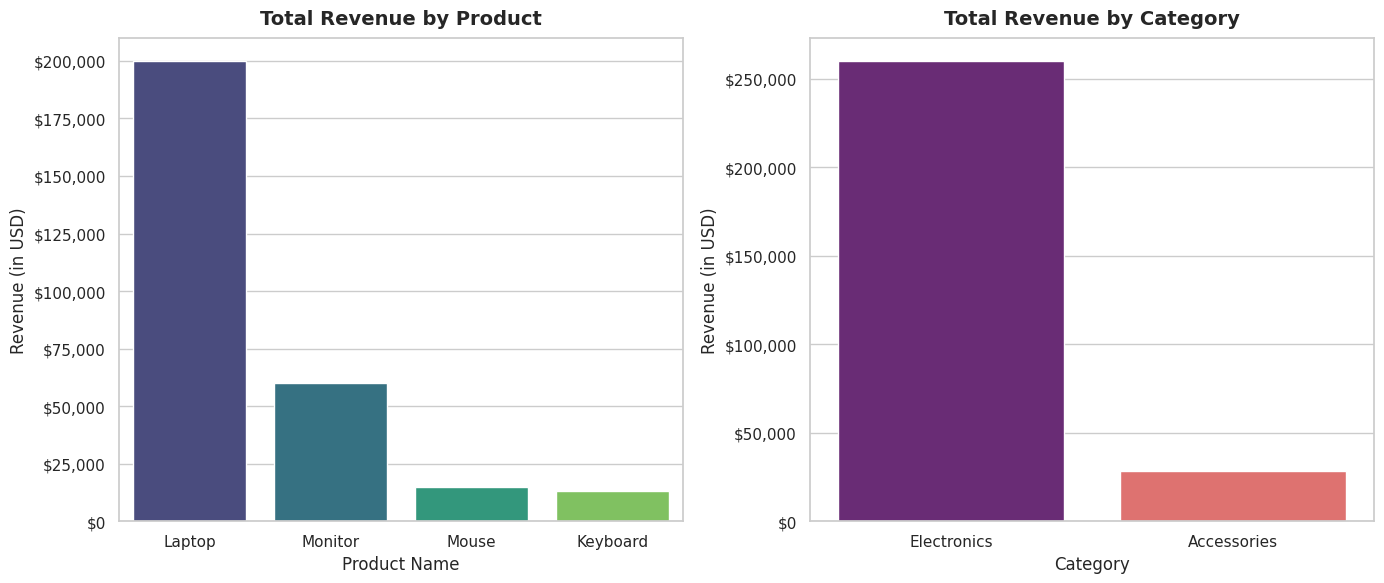

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare aggregated data
product_rev = df.groupby('Product')['Revenue'].sum().reset_index().sort_values(by='Revenue', ascending=False)
category_rev = df.groupby('Category')['Revenue'].sum().reset_index().sort_values(by='Revenue', ascending=False)

# Create a side-by-side layout for the bar charts
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.set_theme(style="whitegrid")

# 1. Bar chart of revenue by product (setting hue to Product and legend to False to fix warnings)
sns.barplot(ax=axes[0], x='Product', y='Revenue', data=product_rev, hue='Product', palette='viridis', legend=False)
axes[0].set_title('Total Revenue by Product', fontsize=14, fontweight='bold', pad=10)
axes[0].set_xlabel('Product Name', fontsize=12)
axes[0].set_ylabel('Revenue (in USD)', fontsize=12)
# Format y-axis numbers as currency
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "${:,}".format(int(x))))

# 2. Bar chart of revenue by category (setting hue to Category and legend to False to fix warnings)
sns.barplot(ax=axes[1], x='Category', y='Revenue', data=category_rev, hue='Category', palette='magma', legend=False)
axes[1].set_title('Total Revenue by Category', fontsize=14, fontweight='bold', pad=10)
axes[1].set_xlabel('Category', fontsize=12)
axes[1].set_ylabel('Revenue (in USD)', fontsize=12)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "${:,}".format(int(x))))

plt.tight_layout()
plt.show()

### Main Business Insights:

1. **High-Value Drivers (Electronics Dominance)**:
   * **Electronics** is by far your primary revenue driver, generating **$260,000** of your total **$288,200** (roughly **90%** of total revenue).
   * **Accessories** only accounts for **$28,200** (about **10%**).

2. **The Flagship Product (Laptops)**:
   * **Laptops** alone generated **$200,000**, which makes up **69.4%** of the company's total revenue. Even with a low sales volume (only 4 units sold), its high unit price of $50,000 makes it the critical pillar of your current business model.

3. **Volume vs. Value Discrepancy**:
   * High-volume accessory items like **Mice** (30 units sold across multiple transactions) and **Keyboards** (11 units sold) generate minimal revenue ($15,000 and $13,200 respectively).
   * While accessories represent customer transaction frequency, they do not currently drive meaningful financial scale.